# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Евсеев Данила  
**Дата:** 13 октября 2026 года  
**Среда:** Python 3.12; точные версии показаны в первой ячейке и requirements.txt.

**Источники:** [учебная таблица NHL](https://www.scrapethissite.com/pages/forms/),
[scikit-learn: предотвращение утечек](https://scikit-learn.org/stable/common_pitfalls.html),
[ROC-AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html),
[pandas.merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html).

**Инструменты:** pandas, NumPy, requests, Beautiful Soup, scikit-learn, matplotlib,
Jupyter/nbclient и pytest. **Использование ИИ:** OpenAI Codex использован для
подготовки кода, пояснений, тестов и отладки. Результаты получены реальным
выполнением ноутбука; автору необходимо понимать решение и уметь объяснить его.

**Порядок работы:** исходная выгрузка → проверки и пары → временное разбиение →
EDA на train → два ориентира → логистическая регрессия → один эксперимент на
validation → фиксация решения → test и разбор ошибок. Файлы в `src/` — часть
решения: запускайте ноутбук вместе со всей папкой проекта.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from src.hockey import URL, COLUMNS, collect_data, load_raw, build_pairs, split_pairs, validate_raw

%matplotlib inline
warnings.filterwarnings("error", category=RuntimeWarning)
warnings.filterwarnings("error", category=ConvergenceWarning)
SEED = 42
ROOT = Path.cwd()
assert (ROOT / "src" / "hockey.py").exists(), "Запустите ноутбук из корня проекта hockey_astra."
DATA = ROOT / "data"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 120, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})

def show_answer(text):
    display(Markdown(text))

def save_plot(name):
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

environment = {name: version(name) for name in
               ["pandas", "numpy", "scikit-learn", "matplotlib", "requests", "beautifulsoup4",
                "nbformat", "nbclient", "ipykernel"]}
print("Python:", platform.python_version())
display(pd.Series(environment, name="Версия"))

Python: 3.12.14


pandas             3.0.1
numpy              2.5.4
scikit-learn       1.9.1
matplotlib        3.11.2
requests          2.34.2
beautifulsoup4    4.15.0
nbformat          5.11.1
nbclient          0.11.0
ipykernel          7.4.0
Name: Версия, dtype: str

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
# По умолчанию используется сохранённая выгрузка: исследование работает без сети.
# Для явного повторного сбора установите REFRESH_DATA = True.
REFRESH_DATA = False
if REFRESH_DATA or not (DATA / "hockey_raw.csv").exists():
    collect_data(DATA)
raw, collection = load_raw(DATA)
page_log = pd.DataFrame(collection["pages"])
assert collection["page_count"] == len(page_log)
assert page_log["page"].tolist() == list(range(1, len(page_log) + 1))
assert page_log["rows"].sum() == len(raw)
assert len(page_log) > 1 and len(raw) > page_log.iloc[0]["rows"]
display(page_log[["page", "rows"]].T)
display(raw.head())
display(raw.tail())
show_answer(f"**Результат 1.1.** Источник: [{URL}]({URL}). "
            f"Сбор: `{collection['collected_at_utc']}` (UTC). "
            f"Обработано **{len(page_log)} страниц**, получено **{len(raw)} строк**; "
            f"на первой странице {page_log.iloc[0]['rows']} строк. "
            "Все номера страниц последовательны; сумма их размеров совпадает с CSV. "
            "CSV повторно прочитан, типы восстановлены, SHA-256 проверен по метаданным.")

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
page,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
rows,25,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,7


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,<NA>,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,<NA>,0.388,292,278,14
2,Calgary Flames,1990,46,26,<NA>,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,<NA>,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,<NA>,0.425,273,298,-25


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10,0.451,225,246,-21


**Результат 1.1.** Источник: [https://www.scrapethissite.com/pages/forms/](https://www.scrapethissite.com/pages/forms/). Сбор: `2026-10-13T20:49:43.833773+00:00` (UTC). Обработано **24 страниц**, получено **582 строк**; на первой странице 25 строк. Все номера страниц последовательны; сумма их размеров совпадает с CSV. CSV повторно прочитан, типы восстановлены, SHA-256 проверен по метаданным.

**Ответ 1.1:**

Сбор реализован в `src/hockey.py`: HTML разбирается по классам ячеек, номера страниц берутся из блока пагинации. Используются тайм-ауты, повторные GET при временных ошибках и пауза между запросами. Исходный CSV записывается после обхода и проверки всех страниц. Таблица журнала, начало и конец выгрузки, дата и контрольная сумма показаны выше.

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [3]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "unique": raw.nunique()})
display(quality)
checks = validate_raw(raw)
display(checks.to_frame())
season_summary = raw.groupby("year").agg(
    teams=("team", "size"), mean_GF=("goals_for", "mean"),
    mean_GA=("goals_against", "mean"), median_win_rate=("win_rate", "median"),
    missing_OT=("ot_losses", lambda x: x.isna().sum()))
season_summary["GF_minus_GA_total"] = raw.groupby("year")["goal_diff"].sum()
display(season_summary)
missing_years = sorted(set(range(int(raw.year.min()), int(raw.year.max()) + 1)) - set(raw.year))
print("Дубликаты team-year:", raw.duplicated(["team", "year"]).sum())
print("Полностью отсутствующие метки лет:", missing_years)
print("Всего уникальных названий команд:", raw.team.nunique())
# wins/(wins+losses+OT) не является определением исходного win_rate:
# в старых сезонах эта сумма не учитывает ничьи. Исходные доли не пересчитываем.
known_outcomes = raw.wins + raw.losses + raw.ot_losses.fillna(0)
display(raw.assign(known_outcomes=known_outcomes)[
    ["team", "year", "wins", "losses", "ot_losses", "win_rate", "known_outcomes"]].head(3))
show_answer(f"**Результат 1.2.** Все {int(checks.sum())} обязательных проверок пройдены. "
            f"Пропущено {int(raw.ot_losses.isna().sum())} значений `ot_losses`; "
            "в исходном CSV они сохранены пустыми. Пропуски имеют сезонную структуру, "
            "поэтому не трактуются как нулевые поражения и этот столбец не включён в модель. "
            f"Отсутствующие годы: {missing_years}. Сохраняю точные названия и метки лет сайта. "
            "Согласованность разности голов проверена построчно; баланс голов лиги показан отдельно. "
            "Корректность всей исторической статистики внешними данными не подтверждалась.")

,dtype,missing,unique
team,string,0,35
year,Int64,0,21
wins,Int64,0,47
losses,Int64,0,47
ot_losses,Int64,224,18
win_rate,float64,0,94
goals_for,Int64,0,172
goals_against,Int64,0,169
goal_diff,Int64,0,178


,passed
nonempty_table,True
unique_team_year,True
required_values_present,True
nonempty_team_names,True
win_rate_between_0_and_1,True
nonnegative_counts,True
goal_diff_equals_GF_minus_GA,True


,teams,mean_GF,mean_GA,median_win_rate,missing_OT,GF_minus_GA_total
year,,,,,,
1990,21,276.4286,276.4286,0.4250,21,0
1991,22,278.3182,278.3182,0.4440,22,0
1992,24,304.625,304.625,0.4760,24,0
1993,26,272.3462,272.3462,0.4640,26,0
1994,26,143.3462,143.3462,0.4275,26,0
1995,26,257.7308,257.7308,0.4330,26,0
1996,26,239.0769,239.0769,0.4270,26,0
1997,26,216.3077,216.3077,0.4270,26,0
1998,27,215.9259,215.9259,0.4150,27,0


Дубликаты team-year: 0
Полностью отсутствующие метки лет: [2004]
Всего уникальных названий команд: 35


,team,year,wins,losses,ot_losses,win_rate,known_outcomes
0,Boston Bruins,1990,44,24,<NA>,0.550,68
1,Buffalo Sabres,1990,31,30,<NA>,0.388,61
2,Calgary Flames,1990,46,26,<NA>,0.575,72


**Результат 1.2.** Все 7 обязательных проверок пройдены. Пропущено 224 значений `ot_losses`; в исходном CSV они сохранены пустыми. Пропуски имеют сезонную структуру, поэтому не трактуются как нулевые поражения и этот столбец не включён в модель. Отсутствующие годы: [2004]. Сохраняю точные названия и метки лет сайта. Согласованность разности голов проверена построчно; баланс голов лиги показан отдельно. Корректность всей исторической статистики внешними данными не подтверждалась.

**Ответ 1.2:**

Таблица качества и сезонная сводка выше показывают типы и структуру пропусков. Проверки включают уникальность `(team, year)`, границы доли побед, неотрицательные счётчики и точное равенство `goal_diff = goals_for − goals_against`. Пустой `ot_losses` сохраняется как пропуск. Сумма `wins + losses + ot_losses` не является надёжным числом игр в старых сезонах, поэтому долю побед сайта не пересчитываю.

В выгрузке 35 точных названий команд и 21 метка сезона. Все 224 пропуска OT относятся к 1990–1998 годам; начиная с 1999 пропусков нет. Баланс суммы забитых и пропущенных голов равен нулю в каждом году. Это проверка внутренней согласованности, а не доказательство полноты внешней истории.

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [4]:
pairs, excluded = build_pairs(raw)
excluded_by_year = excluded.groupby("year").size().rename("excluded_rows")
display(excluded_by_year.to_frame())
print("Пар:", len(pairs), "Исключённых строк:", len(excluded))
ties = pairs.future_win_rate.eq(pairs.future_median)
print("Равенство будущей медиане:", int(ties.sum()))
assert pairs.target_year.sub(pairs.year).eq(1).all()
assert pairs.target.eq(pairs.future_win_rate.gt(pairs.future_median).astype(int)).all()
assert len(pairs) + len(excluded) == len(raw)

# Независимые ручные примеры: положительный класс и равенство медиане (или ниже).
positive = pairs.loc[pairs.target.eq(1)].iloc[0]
nonpositive = pairs.loc[ties].iloc[0] if ties.any() else pairs.loc[pairs.target.eq(0)].iloc[0]
for example in [positive, nonpositive]:
    values = sorted(raw.loc[raw.year.eq(example.target_year), "win_rate"].tolist())
    n = len(values)
    manual_median = values[n // 2] if n % 2 else (values[n // 2 - 1] + values[n // 2]) / 2
    future_value = raw.loc[raw.team.eq(example.team) & raw.year.eq(example.target_year), "win_rate"].item()
    manual_target = int(future_value > manual_median)
    assert np.isclose(manual_median, example.future_median)
    assert manual_target == example.target
    print(f"{example.team}: {int(example.year)} → {int(example.target_year)}")
    print(f"Все {n} будущих долей побед: {values}")
    print(f"Медиана={manual_median:.4f}; будущая доля={future_value:.4f}; "
          f"{future_value:.4f} > {manual_median:.4f}: {bool(manual_target)}; target={manual_target}\n")

# Полный список исключений помогает проверить переименования и край таблицы.
excluded.to_csv(RESULTS / "excluded_rows.csv", index=False)
display(excluded.loc[~excluded.year.eq(raw.year.max()), ["team", "year", "target_year"]])
show_answer(f"**Результат 2.1.** Получено **{len(pairs)} пар**, исключено **{len(excluded)} строк**. "
            f"Равенств медиане: **{int(ties.sum())}**, во всех случаях `target=0`. "
            "Медиана рассчитана по всем командам будущего года до соединения. "
            "Приведены два независимых расчёта по отсортированным долям побед. "
            "Годы без следующей календарной метки, последнее наблюдение и исчезнувшие названия "
            "не создают пары. Полный список сохранён в `results/excluded_rows.csv`.")

,excluded_rows
year,
1992,1
1994,1
1995,1
1996,1
2003,30
2005,1
2010,1
2011,30


Пар: 516 Исключённых строк: 66
Равенство будущей медиане: 23
Boston Bruins: 1990 → 1991
Все 22 будущих долей побед: [0.212, 0.25, 0.325, 0.375, 0.388, 0.388, 0.4, 0.4, 0.412, 0.425, 0.438, 0.45, 0.45, 0.45, 0.45, 0.475, 0.487, 0.512, 0.525, 0.537, 0.562, 0.625]
Медиана=0.4440; будущая доля=0.4500; 0.4500 > 0.4440: True; target=1

New Jersey Devils: 1991 → 1992
Все 24 будущих долей побед: [0.119, 0.131, 0.274, 0.31, 0.31, 0.405, 0.429, 0.429, 0.44, 0.452, 0.464, 0.476, 0.476, 0.476, 0.512, 0.512, 0.524, 0.548, 0.56, 0.56, 0.56, 0.571, 0.607, 0.667]
Медиана=0.4760; будущая доля=0.4760; 0.4760 > 0.4760: False; target=0



,team,year,target_year
51,Minnesota North Stars,1992,1993
111,Quebec Nordiques,1994,1995
144,Winnipeg Jets,1995,1996
155,Hartford Whalers,1996,1997
342,Mighty Ducks of Anaheim,2003,2004
343,Atlanta Thrashers,2003,2004
344,Boston Bruins,2003,2004
345,Buffalo Sabres,2003,2004
346,Calgary Flames,2003,2004
347,Carolina Hurricanes,2003,2004


**Результат 2.1.** Получено **516 пар**, исключено **66 строк**. Равенств медиане: **23**, во всех случаях `target=0`. Медиана рассчитана по всем командам будущего года до соединения. Приведены два независимых расчёта по отсортированным долям побед. Годы без следующей календарной метки, последнее наблюдение и исчезнувшие названия не создают пары. Полный список сохранён в `results/excluded_rows.csv`.

**Ответ 2.1:**

Используется `merge` по точному названию и `target_year = year + 1` с контролем `one_to_one`. Будущая медиана вычисляется до отбора пар. Строгое сравнение `>` относит равенства к классу 0. Числа пар, исключений, равенств и два ручных расчёта показаны выше; исключения дополнительно сохранены в CSV.

Итог: 516 пар, 66 исключений, 23 равенства медиане. Исключения по текущему году: 1992, 1994, 1995, 1996 — по одной строке; 2003 — 30; 2005 — 1; 2010 — 1; 2011 — 30. Разрыв 2003 → 2005 не соединяется. Вручную проверены Boston Bruins 1990 → 1991 (0.450 > 0.444, класс 1) и New Jersey Devils 1991 → 1992 (0.476 = 0.476, класс 0).

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [5]:
splits = split_pairs(pairs)
train, validation, test = (splits[name] for name in ["train", "validation", "test"])
split_summary = pd.DataFrame([
    {"split": name, "target_years": ", ".join(map(str, sorted(frame.target_year.unique()))),
     "rows": len(frame), "class_1_share": frame.target.mean()}
    for name, frame in splits.items()]).set_index("split")
display(split_summary)
assert train.target_year.max() < validation.target_year.min() < test.target_year.min()
assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
# Размер и баланс test показаны по требованию, метрики и ошибки пока не исследуются.

,target_years,rows,class_1_share
split,,,
train,"1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003",338,0.4911
validation,"2006, 2007, 2008",89,0.4719
test,"2009, 2010, 2011",89,0.4719


**Ответ 2.2:**

Границы заданы по **target_year**, а не `year`. `future_win_rate` и `future_median` недоступны после сезона t, поэтому они запрещены в признаках; `target` также запрещён. `target_year` — служебный столбец разбиения и в модель не входит. Случайный split перемешал бы прошлое и будущее: модель обучалась бы на более поздних сезонах, соседние наблюдения одной команды попадали бы в разные части. Это проверяло бы интерполяцию по общей эпохе вместо прогноза ещё не наблюдавшихся лет. Пересечение названий команд между временными частями допустимо для прогноза существующих команд.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

In [6]:
questions = pd.DataFrame([
    {"Вопрос": "Сохраняется ли преимущество по доле побед в следующем году?",
     "Ожидание": "У высоких текущих win_rate чаще target=1.",
     "Решение": "Использовать win_rate и сравнивать модель с его ранжированием."},
    {"Вопрос": "Сопоставимы ли абсолютные голы между сезонами?",
     "Ожидание": "Средняя результативность меняется; абсолютные голы зависят от эпохи.",
     "Решение": "Проверить сезонную нормировку GF и GA одним экспериментом."},
    {"Вопрос": "Связана ли текущая разность голов с будущим классом?",
     "Ожидание": "Положительная разность чаще предшествует target=1.",
     "Решение": "Оставить атаку и защиту; не дублировать их линейной разностью."},
])
display(questions)

,Вопрос,Ожидание,Решение
0,Сохраняется ли преимущество по доле побед в следующем году?,У высоких текущих win_rate чаще target=1.,Использовать win_rate и сравнивать модель с его ранжированием.
1,Сопоставимы ли абсолютные голы между сезонами?,Средняя результативность меняется; абсолютные голы зависят от эпохи.,Проверить сезонную нормировку GF и GA одним экспериментом.
2,Связана ли текущая разность голов с будущим классом?,Положительная разность чаще предшествует target=1.,Оставить атаку и защиту; не дублировать их линейной разностью.


**Ответ 3.1:**

Вопросы, ожидания и влияние на решение записаны в таблице **до основных графиков**. Связь с target исследуется на train. Validation используется для сравнения моделей, test — после фиксации выбора.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

,rows,mean_win_rate,future_success
win_rate_bin,,,
"(0.118, 0.366]",90,0.3049,0.2111
"(0.366, 0.439]",86,0.4101,0.3605
"(0.439, 0.512]",89,0.4794,0.5955
"(0.512, 0.756]",73,0.5709,0.8630


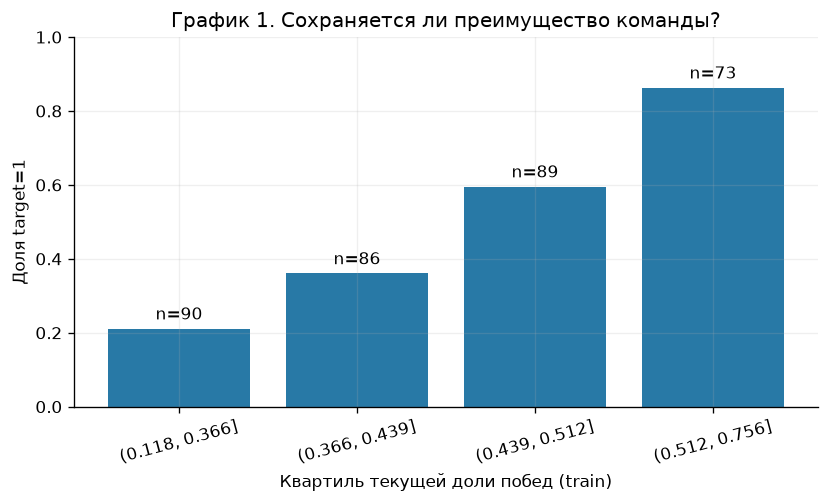

,teams,mean_GF,mean_GA
year,,,
1990,21,276.4286,276.4286
1991,22,278.3182,278.3182
1992,24,304.625,304.625
1993,26,272.3462,272.3462
1994,26,143.3462,143.3462
1995,26,257.7308,257.7308
1996,26,239.0769,239.0769
1997,26,216.3077,216.3077
1998,27,215.9259,215.9259


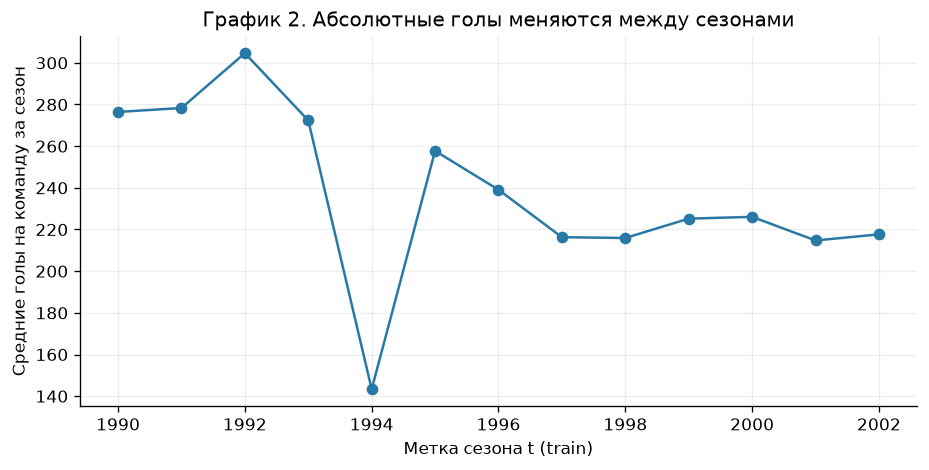

,rows,mean_diff,median_diff,mean_rate
target,,,,
0,172,-22.3314,-14.0,0.3869
1,166,23.2349,27.0,0.4850


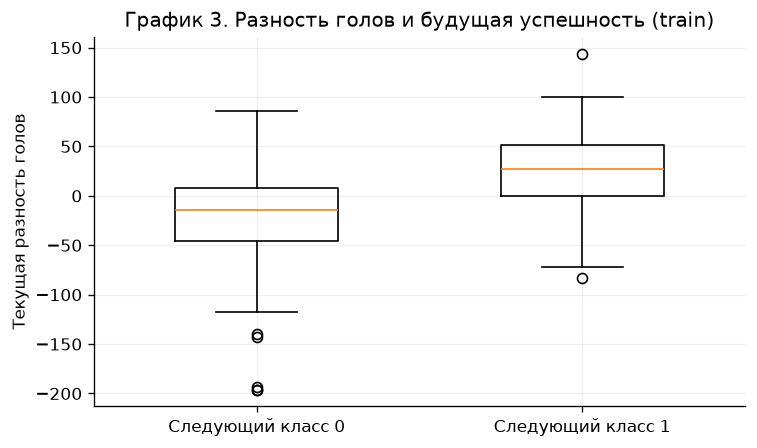

,Пример
team,Detroit Red Wings
year,1995
target_year,1996
win_rate,0.756
future_win_rate,0.463
future_median,0.427
goal_diff,144
target,1


**Результат 3.2.** В нижнем квартиле доли побед доля будущего класса 1 равна **21.1%**, в верхнем — **86.3%** (график 1). Связь полезна для прогноза, но не является причинным эффектом; команды повторяются. Средние голы в train меняются от **143.3** до **304.6** (график 2). Это поддерживает проверку относительных признаков, однако голы за сезон зависят и от числа игр, и от правил; по этому графику нельзя установить причину изменений. Медианная разность голов: **-14.0** для класса 0 и **27.0** для класса 1 (график 3). Перекрытие распределений означает, что одного признака недостаточно. Пример: **Detroit Red Wings, 1995 → 1996**, win_rate 0.756 → 0.463; преимущество может исчезнуть уже на следующий год.

In [7]:
# Все исследования связи признаков с target ограничены train.
train_eda = train.copy()
train_eda["win_rate_bin"] = pd.qcut(train_eda.win_rate, q=4, duplicates="drop")
rate_groups = train_eda.groupby("win_rate_bin", observed=True).agg(
    rows=("target", "size"), mean_win_rate=("win_rate", "mean"), future_success=("target", "mean"))
display(rate_groups)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(rate_groups)), rate_groups.future_success, color="#2879a6")
ax.set_xticks(range(len(rate_groups)), [str(x) for x in rate_groups.index], rotation=15)
ax.set(xlabel="Квартиль текущей доли побед (train)", ylabel="Доля target=1", ylim=(0, 1),
       title="График 1. Сохраняется ли преимущество команды?")
for i, row in enumerate(rate_groups.itertuples()):
    ax.text(i, row.future_success + .025, f"n={row.rows}", ha="center")
save_plot("01_win_rate_success")

train_seasons = raw.loc[raw.year.isin(train.year)].groupby("year").agg(
    teams=("team", "size"), mean_GF=("goals_for", "mean"), mean_GA=("goals_against", "mean"))
display(train_seasons)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_seasons.index, train_seasons.mean_GF, marker="o", color="#2879a6")
ax.set(xlabel="Метка сезона t (train)", ylabel="Средние голы на команду за сезон",
       title="График 2. Абсолютные голы меняются между сезонами")
save_plot("02_season_scoring")

goal_summary = train.groupby("target").agg(rows=("target", "size"),
    mean_diff=("goal_diff", "mean"), median_diff=("goal_diff", "median"),
    mean_rate=("win_rate", "mean"))
display(goal_summary)
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([train.loc[train.target.eq(c), "goal_diff"].astype(float).to_numpy() for c in [0, 1]],
           tick_labels=["Следующий класс 0", "Следующий класс 1"], widths=.5)
ax.set(ylabel="Текущая разность голов", title="График 3. Разность голов и будущая успешность (train)")
save_plot("03_goal_diff_success")

# Конкретная команда: самый большой спад доли побед в train, без просмотра test.
train_eda["win_rate_change"] = train_eda.future_win_rate - train_eda.win_rate
largest_drop = train_eda.sort_values(["win_rate_change", "team"]).iloc[0]
display(largest_drop[["team", "year", "target_year", "win_rate", "future_win_rate",
                      "future_median", "goal_diff", "target"]].to_frame("Пример"))
show_answer(f"**Результат 3.2.** В нижнем квартиле доли побед доля будущего класса 1 "
            f"равна **{rate_groups.future_success.iloc[0]:.1%}**, в верхнем — "
            f"**{rate_groups.future_success.iloc[-1]:.1%}** (график 1). "
            "Связь полезна для прогноза, но не является причинным эффектом; команды повторяются. "
            f"Средние голы в train меняются от **{train_seasons.mean_GF.min():.1f}** до "
            f"**{train_seasons.mean_GF.max():.1f}** (график 2). Это поддерживает проверку "
            "относительных признаков, однако голы за сезон зависят и от числа игр, и от правил; "
            "по этому графику нельзя установить причину изменений. "
            f"Медианная разность голов: **{goal_summary.loc[0, 'median_diff']:.1f}** для класса 0 "
            f"и **{goal_summary.loc[1, 'median_diff']:.1f}** для класса 1 (график 3). "
            "Перекрытие распределений означает, что одного признака недостаточно. "
            f"Пример: **{largest_drop.team}, {int(largest_drop.year)} → {int(largest_drop.target_year)}**, "
            f"win_rate {largest_drop.win_rate:.3f} → {largest_drop.future_win_rate:.3f}; "
            "преимущество может исчезнуть уже на следующий год.")

**Ответ 3.2:**

Графики 1–3 отвечают соответственно на вопросы об устойчивости побед, изменении абсолютных голов и связи разности голов с будущим классом. Числовые сводки и конкретная команда показаны рядом с графиками. Выводы и ограничения интерпретации приведены в результате 3.2.

Отдельная особенность: Detroit Red Wings 1995 → 1996 снизили win_rate с 0.756 до 0.463, однако остались выше будущей медианы 0.427. Значит, сильный спад абсолютной доли побед сам по себе не равен target=0: цель определяется относительно остальных команд.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [8]:
dummy = DummyClassifier(strategy="prior", random_state=SEED)
dummy.fit(train[["win_rate"]], train.target)
dummy_val = dummy.predict_proba(validation[["win_rate"]])[:, 1]
rate_val = validation.win_rate.to_numpy()
baseline_validation = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(validation.target, dummy_val), roc_auc_score(validation.target, rate_val)]},
    index=["Константа train prior", "Текущий win_rate"])
display(baseline_validation)
print("Константная вероятность:", dummy_val[0])

,ROC-AUC
Константа train prior,0.5000
Текущий win_rate,0.7568


Константная вероятность: 0.4911242603550296


**Ответ 4.1:**

Константный `DummyClassifier(strategy="prior")` обучен на train и предсказывает одну и ту же частоту класса 1. Он задаёт случайное ранжирование с AUC=0.5. Текущий win_rate не обучается и проверяет устойчивость силы команд: для дополнительной модели это более содержательная планка, чем константа. win_rate не трактую как калиброванную вероятность следующего класса.

На validation: константа — 0.5000, текущий win_rate — 0.7568. Частота положительного класса train равна 0.4911; при пороге 0.5 константа предсказывает только класс 0.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [9]:
BASE_FEATURES = ["win_rate", "goals_for", "goals_against"]
RELATIVE_FEATURES = ["win_rate", "goals_for_relative", "goals_against_relative"]
FORBIDDEN = {"target", "future_win_rate", "future_median", "target_year"}
assert FORBIDDEN.isdisjoint(BASE_FEATURES + RELATIVE_FEATURES)

def make_logistic():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                           tol=1e-4, random_state=SEED)),
    ])

base_model = make_logistic()
base_model.fit(train[BASE_FEATURES], train.target)
base_val = base_model.predict_proba(validation[BASE_FEATURES])[:, 1]
base_auc = roc_auc_score(validation.target, base_val)
display(baseline_validation.assign(**{"Модель": baseline_validation.index}).set_index("Модель"))
print(f"Логистическая регрессия (исходные голы), validation ROC-AUC: {base_auc:.6f}")
display(pd.Series(base_model.named_steps["classifier"].coef_[0],
                  index=BASE_FEATURES, name="Коэффициент после StandardScaler").to_frame())
assert base_model.named_steps["scaler"].n_samples_seen_ == len(train)
show_answer(f"**Результат 4.2.** ROC-AUC логистической регрессии: **{base_auc:.4f}**; "
            f"разница с win_rate: **{base_auc - baseline_validation.iloc[1, 0]:+.4f}**. "
            "Проверена обучающая выборка масштабировщика. Коэффициенты описывают модель "
            "при прочих включённых признаках; их нельзя считать причинным влиянием, "
            "особенно при корреляции побед и голов.")

,ROC-AUC
Модель,
Константа train prior,0.5000
Текущий win_rate,0.7568


Логистическая регрессия (исходные голы), validation ROC-AUC: 0.774569


,Коэффициент после StandardScaler
win_rate,0.8027
goals_for,0.4269
goals_against,-0.5289


**Результат 4.2.** ROC-AUC логистической регрессии: **0.7746**; разница с win_rate: **+0.0177**. Проверена обучающая выборка масштабировщика. Коэффициенты описывают модель при прочих включённых признаках; их нельзя считать причинным влиянием, особенно при корреляции побед и голов.

**Ответ 4.2:**

Признаки: `win_rate`, `goals_for`, `goals_against`. Победы отражают текущий итог, голы — атаку и защиту. `wins` дублирует информацию о победах и зависит от длины сезона; `goal_diff` линейно выражается через два включённых столбца. Название команды исключено, чтобы не запоминать клуб на малой выборке; год исключён, чтобы не задавать линейную экстраполяцию эпохи. Pipeline содержит медианный imputer, StandardScaler и L2-логистическую регрессию. Все обучаемые преобразования подгоняются только на train; в выбранных исходных признаках фактических пропусков нет.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Гипотеза до запуска:** относительные голы помогут при смене результативности лиги. Меняю только представление GF/GA. Выбор — максимальный validation ROC-AUC; при равенстве сохраняю исходный вариант. Test остаётся закрытым до фиксации выбора.

In [10]:
# Единственное изменение: представление двух голевых признаков относительно своей лиги.
# z_t = (голы команды - средние голы всех команд t) / std голов всех команд t.
# Это доступные данные сезона t; заполнение пропусков и StandardScaler по-прежнему fit на train.
relative_model = make_logistic()
relative_model.fit(train[RELATIVE_FEATURES], train.target)
relative_val = relative_model.predict_proba(validation[RELATIVE_FEATURES])[:, 1]
relative_auc = roc_auc_score(validation.target, relative_val)
experiment = pd.DataFrame({"validation_ROC_AUC": [base_auc, relative_auc]},
                           index=["Исходные голы", "Голы относительно сезона"])
display(experiment)
# Правило записано до запуска: выбираем большее AUC; при равенстве исходный вариант.
use_relative = relative_auc > base_auc
selected_model = relative_model if use_relative else base_model
selected_features = RELATIVE_FEATURES if use_relative else BASE_FEATURES
selected_name = "Голы относительно сезона" if use_relative else "Исходные голы"
selected_val = relative_val if use_relative else base_val
selection = {
    "model": "LogisticRegression", "variant": selected_name, "features": selected_features,
    "parameters": {"C": 1.0, "solver": "lbfgs", "max_iter": 2000, "tol": 1e-4,
                   "random_state": SEED},
    "preprocessing": "SimpleImputer(median) -> StandardScaler; fit only on train",
    "selection_rule": "maximum pooled validation ROC-AUC; original features on tie",
    "refit_on_train_plus_validation": False,
    "validation_auc": float(roc_auc_score(validation.target, selected_val)),
    "threshold": 0.5,
}
(RESULTS / "model_selection.json").write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding="utf-8")
print("Выбор до оценки test:")
display(selection)
show_answer(f"**Результат 4.3.** Изменение ROC-AUC: **{relative_auc - base_auc:+.4f}**. "
            f"Выбран вариант **«{selected_name}»**. Выбор сохранён до вычисления test-прогнозов. "
            "Это один эксперимент на небольшой validation; разница не доказывает "
            "устойчивого преимущества на любых сезонах. Модель сохраняет обучение только на train, "
            "чтобы результаты validation и test относились к одному и тому же обученному решению.")

,validation_ROC_AUC
Исходные голы,0.7746
Голы относительно сезона,0.7660


Выбор до оценки test:


{'model': 'LogisticRegression',
 'variant': 'Исходные голы',
 'features': ['win_rate', 'goals_for', 'goals_against'],
 'parameters': {'C': 1.0,
  'solver': 'lbfgs',
  'max_iter': 2000,
  'tol': 0.0001,
  'random_state': 42},
 'preprocessing': 'SimpleImputer(median) -> StandardScaler; fit only on train',
 'selection_rule': 'maximum pooled validation ROC-AUC; original features on tie',
 'refit_on_train_plus_validation': False,
 'validation_auc': 0.7745694022289767,
 'threshold': 0.5}

**Результат 4.3.** Изменение ROC-AUC: **-0.0086**. Выбран вариант **«Исходные голы»**. Выбор сохранён до вычисления test-прогнозов. Это один эксперимент на небольшой validation; разница не доказывает устойчивого преимущества на любых сезонах. Модель сохраняет обучение только на train, чтобы результаты validation и test относились к одному и тому же обученному решению.

**Ответ 4.3:**

**До эксперимента:** ожидаю, что замена абсолютных GF/GA их положением относительно лиги в сезоне t поможет переносить модель между эпохами с разной результативностью. Меняется только представление двух голевых признаков; алгоритм, C, обработка пропусков и train сохраняются. Сезонные среднее и std считаются по полной таблице текущего сезона t; после его окончания это допустимый контекст для всех команд. Это не обучение StandardScaler на validation: обучаемый scaler всё равно использует только train. Правило выбора: больший pooled validation ROC-AUC; при равенстве исходные признаки. Test не участвует. Результат и окончательная спецификация сохранены в предыдущей ячейке.

Фактический результат: 0.7746 для исходных голов против 0.7660 для относительных, изменение −0.0086. Гипотеза улучшения не подтвердилась на этой validation; финальным остаётся исходный вариант. Это не доказывает бесполезности нормировки на других данных.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

,ROC-AUC,F1@0.5,accuracy@0.5
Константа train prior,0.5000,0.0000,0.5281
Текущий win_rate,0.7404,0.6522,0.6404
Выбранная логистическая регрессия,0.7553,0.6990,0.6517


,ROC-AUC,F1@0.5,accuracy@0.5
validation,,,
Константа train prior,0.5000,0.0000,0.5281
Текущий win_rate,0.7568,0.7292,0.7079
Выбранная логистическая регрессия,0.7746,0.7500,0.7079


,target_year,rows,ROC-AUC,F1@0.5,accuracy@0.5
0,2009,30,0.6696,0.5882,0.5333
1,2010,30,0.7589,0.7647,0.7333
2,2011,29,0.8524,0.7429,0.6897


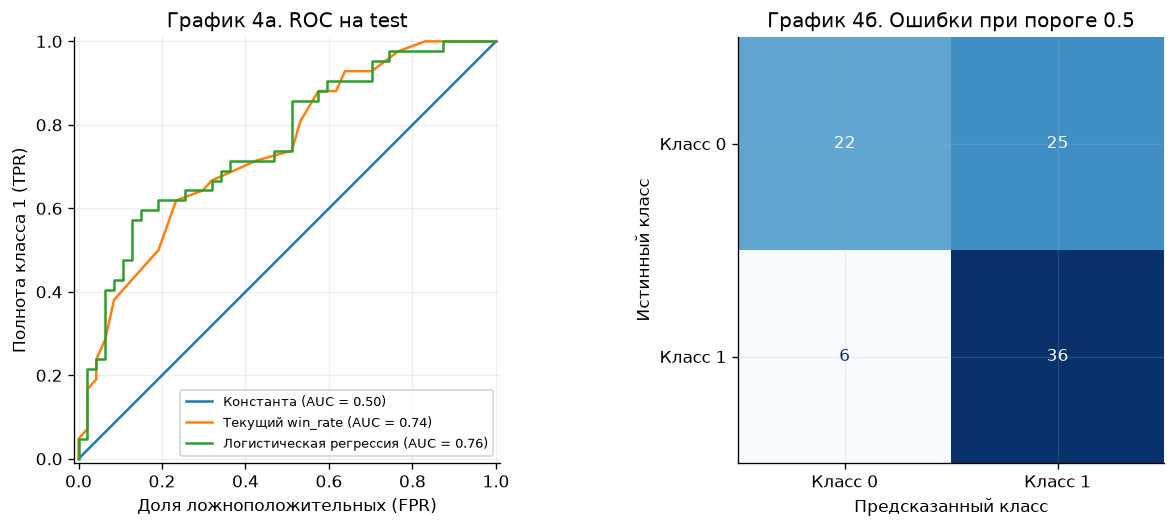

**Результат 5.1.** Выбранная модель: ROC-AUC **0.7553**, F1 **0.6990**, accuracy **0.6517**. Изменение AUC относительно validation: **-0.0193**. ROC-AUC оценивает ранжирование без фиксированного порога; F1 — баланс precision и recall положительного класса; accuracy — долю верных решений всех классов. Текущий win_rate — оценка для ранжирования, а не обученная вероятность будущего успеха; его порог 0.5 приведён по условию. У константы равные оценки и AUC=0.5, но F1 и accuracy зависят от предсказанного класса. Пул AUC может отличаться от среднего AUC по годам. После этой оценки решение не меняется.

In [11]:
# Первый и единственный расчёт вероятностей выбранной модели на test.
# Дальше используются только эти сохранённые прогнозы; fit больше не вызывается.
assert json.loads((RESULTS / "model_selection.json").read_text(encoding="utf-8")) == selection
test_probability = selected_model.predict_proba(test[selected_features])[:, 1]
test_scores = {
    "Константа train prior": dummy.predict_proba(test[["win_rate"]])[:, 1],
    "Текущий win_rate": test.win_rate.to_numpy(),
    "Выбранная логистическая регрессия": test_probability,
}

def metrics(y, score):
    prediction = np.asarray(score) >= .5
    return {"ROC-AUC": float(roc_auc_score(y, score)),
            "F1@0.5": float(f1_score(y, prediction, zero_division=0)),
            "accuracy@0.5": float(accuracy_score(y, prediction))}

test_metrics = pd.DataFrame({name: metrics(test.target, score) for name, score in test_scores.items()}).T
display(test_metrics)
validation_scores = {"Константа train prior": dummy_val, "Текущий win_rate": rate_val,
                     "Выбранная логистическая регрессия": selected_val}
validation_metrics = pd.DataFrame({name: metrics(validation.target, score)
                                   for name, score in validation_scores.items()}).T
display(validation_metrics.rename_axis("validation"))
test_metrics.to_csv(RESULTS / "test_metrics.csv", index_label="model")
validation_metrics.to_csv(RESULTS / "validation_metrics.csv", index_label="model")

test_predictions = test.copy()
test_predictions["probability"] = test_probability
test_predictions["prediction"] = (test_probability >= .5).astype(int)
test_predictions["correct"] = test_predictions.prediction.eq(test_predictions.target)
test_predictions.to_csv(RESULTS / "test_predictions.csv", index=False)
year_metrics = pd.DataFrame([{ "target_year": int(year), "rows": len(frame),
    **metrics(frame.target, frame.probability)} for year, frame in test_predictions.groupby("target_year")])
display(year_metrics)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
short_labels = ["Константа", "Текущий win_rate", "Логистическая регрессия"]
for label, (name, score) in zip(short_labels, test_scores.items()):
    RocCurveDisplay.from_predictions(test.target, score, name=label, ax=axes[0])
axes[0].set_title("График 4а. ROC на test")
axes[0].set(xlabel="Доля ложноположительных (FPR)", ylabel="Полнота класса 1 (TPR)")
axes[0].legend(loc="lower right", fontsize=8)
ConfusionMatrixDisplay.from_predictions(test.target, test_probability >= .5,
    display_labels=["Класс 0", "Класс 1"], colorbar=False, ax=axes[1], cmap="Blues")
axes[1].set_title("График 4б. Ошибки при пороге 0.5")
axes[1].set(xlabel="Предсказанный класс", ylabel="Истинный класс")
plt.tight_layout()
save_plot("04_test_evaluation")
chosen_test = test_metrics.loc["Выбранная логистическая регрессия"]
show_answer(f"**Результат 5.1.** Выбранная модель: ROC-AUC **{chosen_test['ROC-AUC']:.4f}**, "
            f"F1 **{chosen_test['F1@0.5']:.4f}**, accuracy **{chosen_test['accuracy@0.5']:.4f}**. "
            f"Изменение AUC относительно validation: **{chosen_test['ROC-AUC'] - selection['validation_auc']:+.4f}**. "
            "ROC-AUC оценивает ранжирование без фиксированного порога; F1 — баланс precision и recall "
            "положительного класса; accuracy — долю верных решений всех классов. "
            "Текущий win_rate — оценка для ранжирования, а не обученная вероятность будущего успеха; "
            "его порог 0.5 приведён по условию. У константы равные оценки и AUC=0.5, "
            "но F1 и accuracy зависят от предсказанного класса. Пул AUC может отличаться "
            "от среднего AUC по годам. После этой оценки решение не меняется.")

**Ответ 5.1:**

Финальные параметры и признаки зафиксированы в пункте 4.3 и `results/model_selection.json`. Выбранный обученный Pipeline применяется к test один раз; все метрики, годовая сводка и графики используют сохранённые вероятности. Порог 0.5 заранее задан для всех ориентиров и модели. После оценки не выполняются подбор параметров, признаков или порога.

На test выбранная модель: ROC-AUC 0.7553, F1 0.6990, accuracy 0.6517. AUC уменьшился с validation на 0.0193. Преимущество над win_rate на test — около 0.0149; на небольшой зависимой выборке оно не устанавливает статистически доказанного превосходства. Матрица ошибок: TN=22, FP=25, FN=6, TP=36. Модель предсказывает 61 положительный исход при 42 фактических, поэтому высокая полнота сочетается с более низкой точностью положительных прогнозов. Порог сохранён согласно заданию.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [12]:
errors = test_predictions.loc[~test_predictions.correct].copy()
# Уверенность в неверном классе: p для false positive, 1-p для false negative.
errors["wrong_confidence"] = np.where(errors.prediction.eq(1), errors.probability, 1 - errors.probability)
errors["future_margin"] = errors.future_win_rate - errors.future_median
errors["win_rate_change"] = errors.future_win_rate - errors.win_rate
errors["error_type"] = np.where(errors.prediction.eq(1), "FP", "FN")
top_errors = errors.sort_values(["wrong_confidence", "target_year", "team"],
                                ascending=[False, True, True]).head(5)
error_columns = ["team", "year", "target_year", "probability", "prediction", "target", "error_type",
                 "win_rate", "goals_for", "goals_against", "goal_diff", "future_win_rate",
                 "future_median", "future_margin", "win_rate_change", "wrong_confidence"]
display(top_errors[error_columns])
top_errors[error_columns].to_csv(RESULTS / "top_errors.csv", index=False)
display(errors.groupby("error_type").agg(rows=("target", "size"),
    mean_current_rate=("win_rate", "mean"), mean_rate_change=("win_rate_change", "mean")))
print("Всего ошибок:", len(errors), "из", len(test))
show_answer("**Результат 5.2.** Выбраны пять самых уверенных ошибок; при равенстве "
            "сначала меньший target_year, затем алфавитное название. Идентификатор — `(team, year)`. "
            "В таблице показаны и доступные признаки, и будущие величины только для разбора. "
            f"Состав выбранных ошибок: {top_errors.error_type.value_counts().to_dict()}. "
            "**Факт:** модель экстраполирует текущую силу, а в этих строках следующий результат "
            "оказывается с другой стороны медианы. `win_rate_change` показывает направление "
            "изменения, `future_margin` — насколько результат далёк от границы. "
            "**Гипотеза:** резкое изменение состава или вратаря могло изменить силу команды. "
            "Для проверки нужны данные переходов, травм, игрового времени и вратарской "
            "статистики соответствующих сезонов; текущая таблица гипотезу не подтверждает. "
            "Набор специально смещён к уверенным ошибкам и не описывает все команды.")

,team,year,target_year,probability,prediction,target,error_type,win_rate,goals_for,goals_against,goal_diff,future_win_rate,future_median,future_margin,win_rate_change,wrong_confidence
429,Boston Bruins,2008,2009,0.9111,1,0,FP,0.646,274,196,78,0.476,0.488,-0.012,-0.170,0.9111
479,Phoenix Coyotes,2009,2010,0.8246,1,0,FP,0.610,225,202,23,0.524,0.524,0.000,-0.086,0.8246
474,New Jersey Devils,2009,2010,0.8090,1,0,FP,0.585,222,191,31,0.463,0.524,-0.061,-0.122,0.8090
499,Los Angeles Kings,2010,2011,0.7604,1,0,FP,0.561,219,198,21,0.488,0.500,-0.012,-0.073,0.7604
460,Buffalo Sabres,2009,2010,0.7516,1,0,FP,0.549,235,207,28,0.524,0.524,0.000,-0.025,0.7516


,rows,mean_current_rate,mean_rate_change
error_type,,,
FN,6,0.4268,0.1362
FP,25,0.5312,-0.0806


Всего ошибок: 31 из 89


**Результат 5.2.** Выбраны пять самых уверенных ошибок; при равенстве сначала меньший target_year, затем алфавитное название. Идентификатор — `(team, year)`. В таблице показаны и доступные признаки, и будущие величины только для разбора. Состав выбранных ошибок: {'FP': 5}. **Факт:** модель экстраполирует текущую силу, а в этих строках следующий результат оказывается с другой стороны медианы. `win_rate_change` показывает направление изменения, `future_margin` — насколько результат далёк от границы. **Гипотеза:** резкое изменение состава или вратаря могло изменить силу команды. Для проверки нужны данные переходов, травм, игрового времени и вратарской статистики соответствующих сезонов; текущая таблица гипотезу не подтверждает. Набор специально смещён к уверенным ошибкам и не описывает все команды.

**Ответ 5.2:**

Разбираются пять наиболее уверенных неверных прогнозов по детерминированному правилу. Это целенаправленно выбранные случаи, а не случайная выборка ошибок. Будущие доля побед и медиана используются здесь только для объяснения уже готовых прогнозов. Сводка разделяет ложноположительные (FP) и ложноотрицательные (FN) ошибки; гипотеза о кадровых изменениях явно отделена от наблюдаемых чисел.

**Общие факты:** все пять выбранных ошибок — FP; у каждой команды текущий win_rate выше 0.5 и разность голов положительна, но будущий win_rate снизился. **Различия:** Boston Bruins потеряли 0.170 по доле побед; у Buffalo Sabres спад только 0.025. Phoenix Coyotes и Buffalo Sabres точно равны будущей медиане, поэтому дают класс 0 из-за строгого неравенства. Boston Bruins и Los Angeles Kings ниже границы на 0.012, New Jersey Devils — на 0.061. Следовательно, в наборе есть и пограничные случаи, и более глубокий спад. В полном test 25 FP и 6 FN; у FN среднее изменение win_rate +0.1362, у FP −0.0806. Это описательная сводка выбранных исходов, а не причинное объяснение.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [13]:
manifest = {
    "author": "Евсеев Данила", "date": "2026-10-13", "python": platform.python_version(),
    "versions": environment, "source_sha256": collection["csv_sha256"],
    "raw_rows": len(raw), "pairs": len(pairs), "excluded_rows": len(excluded),
    "split_rows": {name: len(frame) for name, frame in splits.items()},
    "selection": selection, "test_metrics": test_metrics.to_dict(orient="index"),
}
(RESULTS / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
assert not test_predictions.probability.isna().any()
assert test_predictions.probability.between(0, 1).all()
assert selected_model.named_steps["scaler"].n_samples_seen_ == len(train)
print("Все итоговые проверки пройдены. Параметры и окружение: results/run_manifest.json")
show_answer(f"**Результат 6.1.** Временной прогноз содержит сигнал: верхний квартиль текущей "
            f"доли побед чаще успешен в будущем (график 1), итоговый AUC модели — "
            f"**{chosen_test['ROC-AUC']:.4f}** (таблица 5.1). "
            "**Подтверждённые решения:** (1) после сезонной сводки сохранены пропуски OT и "
            "точные календарные пары, включая исключение разрыва лет; (2) после графика 1 "
            "win_rate оставлен как признак и сильный ориентир. "
            f"**Решение по эксперименту:** сравнение 4.3 закрепило вариант «{selected_name}». "
            "Не выполнялся широкий поиск алгоритмов и параметров: небольшая validation "
            "повышает риск подгонки, а условия оценивают обоснованность одного эксперимента. "
            "Ограничения: историческая учебная выборка, повторяющиеся команды, всего три года test, "
            "округлённый win_rate, исключение переименований, отсутствие состава/травм и числа игр. "
            "Высокая метрика не гарантирует качество на современной NHL. "
            "Воспроизведение: зафиксированные зависимости, CSV с SHA-256, запуск всех ячеек "
            "сверху вниз; выбор записывается раньше test, seed=42, порог=0.5.")

Все итоговые проверки пройдены. Параметры и окружение: results/run_manifest.json


**Результат 6.1.** Временной прогноз содержит сигнал: верхний квартиль текущей доли побед чаще успешен в будущем (график 1), итоговый AUC модели — **0.7553** (таблица 5.1). **Подтверждённые решения:** (1) после сезонной сводки сохранены пропуски OT и точные календарные пары, включая исключение разрыва лет; (2) после графика 1 win_rate оставлен как признак и сильный ориентир. **Решение по эксперименту:** сравнение 4.3 закрепило вариант «Исходные голы». Не выполнялся широкий поиск алгоритмов и параметров: небольшая validation повышает риск подгонки, а условия оценивают обоснованность одного эксперимента. Ограничения: историческая учебная выборка, повторяющиеся команды, всего три года test, округлённый win_rate, исключение переименований, отсутствие состава/травм и числа игр. Высокая метрика не гарантирует качество на современной NHL. Воспроизведение: зафиксированные зависимости, CSV с SHA-256, запуск всех ячеек сверху вниз; выбор записывается раньше test, seed=42, порог=0.5.

**Ответ 6.1:**

Основные результаты и ограничения приведены выше. `results/run_manifest.json` фиксирует версии, контрольную сумму, размеры выборок, выбранное решение и итоговые метрики. В README приведены команды запуска, источники и честное описание использования Codex. Автоматические тесты проверяют полноту будущей медианы, равенство, календарные разрывы, имена, дубликаты, границы split, HTML и отсутствие влияния будущих голов на текущие относительные признаки.